# 02 · Preprocessing and exploratory data analysis

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from IPython.display import Image, display
from src import config as C

## Cleaning and the 30-minute grid
Each step and its row count is logged by `src/data_preprocessing.py`.

In [2]:
from src.data_preprocessing import load_raw, clean, to_slot_grid
raw = load_raw()
cleaned, clean_log = clean(raw)
grid, grid_log = to_slot_grid(cleaned)
clean_log, grid_log

({'rows_in': 35717,
  'after_dropping_exact_duplicates': 35501,
  'negative_occupancy_clipped_to_zero': 12,
  'rates_above_1_capped': 373,
  'sparse_parks_dropped': {'BHMBRTARC01': 88, 'NIA North': 159},
  'rows_out': 35254,
  'parks_out': 28},
 {'readings_snapped_to_grid': 34962,
  'readings_outside_grid_dropped': 292,
  'slots_with_multiple_readings_averaged': 17,
  'grid_rows': 36792,
  'grid_missing_slots': 1847,
  'grid_missing_pct': 5.02,
  'grid_days': 73})

In [3]:
grid.head(20)

,SystemCodeNumber,slot_time,capacity,occupied,occupancy_rate,n_readings,date,slot,status
0,BHMBCCMKT01,2016-10-04 08:00:00,577,61.0,0.105719,1,2016-10-04,0,LOW
1,BHMBCCMKT01,2016-10-04 08:30:00,577,64.0,0.110919,1,2016-10-04,1,LOW
2,BHMBCCMKT01,2016-10-04 09:00:00,577,80.0,0.138648,1,2016-10-04,2,LOW
3,BHMBCCMKT01,2016-10-04 09:30:00,577,107.0,0.185442,1,2016-10-04,3,LOW
4,BHMBCCMKT01,2016-10-04 10:00:00,577,150.0,0.259965,1,2016-10-04,4,LOW
5,BHMBCCMKT01,2016-10-04 10:30:00,577,177.0,0.306759,1,2016-10-04,5,LOW
6,BHMBCCMKT01,2016-10-04 11:00:00,577,219.0,0.379549,1,2016-10-04,6,LOW
7,BHMBCCMKT01,2016-10-04 11:30:00,577,247.0,0.428076,1,2016-10-04,7,LOW
8,BHMBCCMKT01,2016-10-04 12:00:00,577,259.0,0.448873,1,2016-10-04,8,LOW
9,BHMBCCMKT01,2016-10-04 12:30:00,577,266.0,0.461005,1,2016-10-04,9,LOW


Decisions and why:
* **Drop exact duplicates** (216) – they would double-count a reading.
* **Clip negative occupancy to 0** (12 rows) – a count cannot be negative.
* **Cap the rate at 1.0** (373 rows) – a car park cannot be more than full; the raw count is kept separately.
* **Drop car parks with < 500 readings** (2 parks) – too sparse to provide training days.
* **Snap readings to the nearest 30-minute slot if within 10 minutes**, average if two land in one slot (17 cases) – turns irregular timestamps into a regular series so that 'one slot ahead' always means 30 minutes.
* **Never interpolate** missing slots (5.0% of the grid) – an invented value could become a training target.

## Exploratory analysis
`src/eda.py` draws every figure and stores the quoted numbers in `outputs/metrics/eda_summary.json`.

In [4]:
from src.eda import run as run_eda
eda = run_eda()

{
  "occupancy_rate_mean": 0.4972,
  "occupancy_rate_median": 0.4763,
  "status_share": {
    "LOW": 0.5229,
    "MODERATE": 0.2591,
    "HIGH": 0.1318,
    "FULL": 0.0862
  },
  "hour_profile_mean": {
    "08:00": 0.2146,
    "08:30": 0.2603,
    "09:00": 0.3239,
    "09:30": 0.3741,
    "10:00": 0.4302,
    "10:30": 0.4756,
    "11:00": 0.5157,
    "11:30": 0.5471,
    "12:00": 0.5749,
    "12:30": 0.5918,
    "13:00": 0.6064,
    "13:30": 0.6113,
    "14:00": 0.6157,
    "14:30": 0.6057,
    "15:00": 0.589,
    "15:30": 0.5637,
    "16:00": 0.5319,
    "16:30": 0.4879
  },
  "peak_time": "14:00",
  "peak_mean_rate": 0.6157,
  "lowest_time": "08:00",
  "weekday_mean": {
    "Mon": 0.5163,
    "Tue": 0.542,
    "Wed": 0.5421,
    "Thu": 0.5495,
    "Fri": 0.5192,
    "Sat": 0.4308,
    "Sun": 0.3557
  },
  "weekday_vs_weekend_mean": {
    "weekday": 0.5339,
    "weekend": 0.3934
  },
  "most_often_full": [
    "BHMBRCBRG01",
    "BHMNCPNHS01",
    "BHMBCCTHL01",
    "BHMEURBRD02",
   

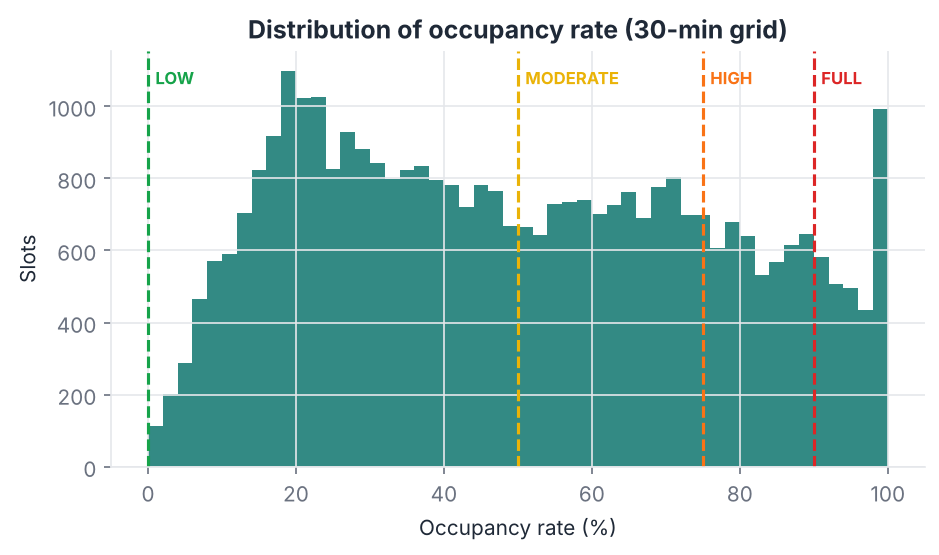

In [5]:
display(Image(ROOT / 'outputs/figures/eda_01_occupancy_distribution.png'))

The distribution is wide (mean ≈ 49%) with a spike at 100%: some car parks fill completely. About 9% of slots are FULL (≥ 90%), so FULL is a minority class – plain accuracy would hide poor FULL detection, hence macro-F1 and FULL recall later.

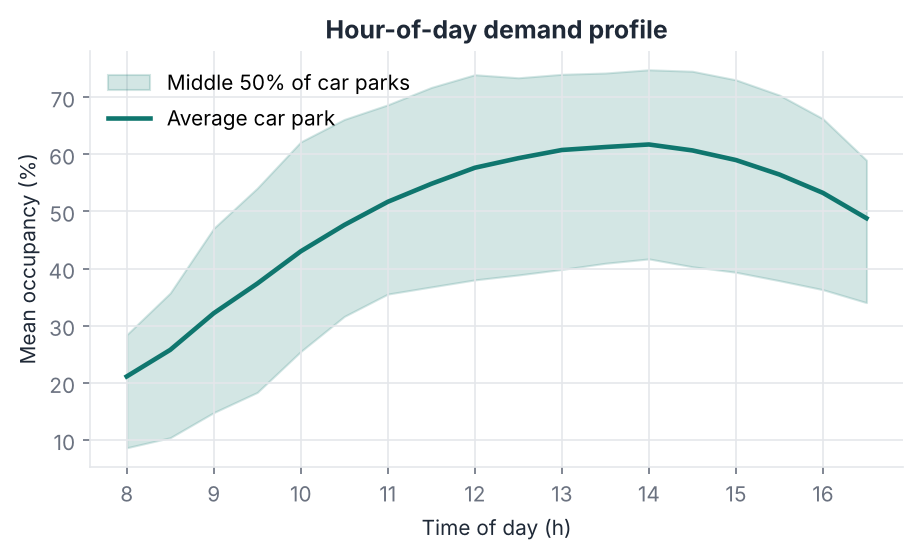

('14:00', 0.6157)

In [6]:
display(Image(ROOT / 'outputs/figures/eda_02_hour_of_day_profile.png'))
eda['peak_time'], eda['peak_mean_rate']

Occupancy climbs from 08:00 to a peak around 14:00 and then falls. Time of day must be a feature, and because the curve is steepest in the morning, persistence ('no change') will be worst there.

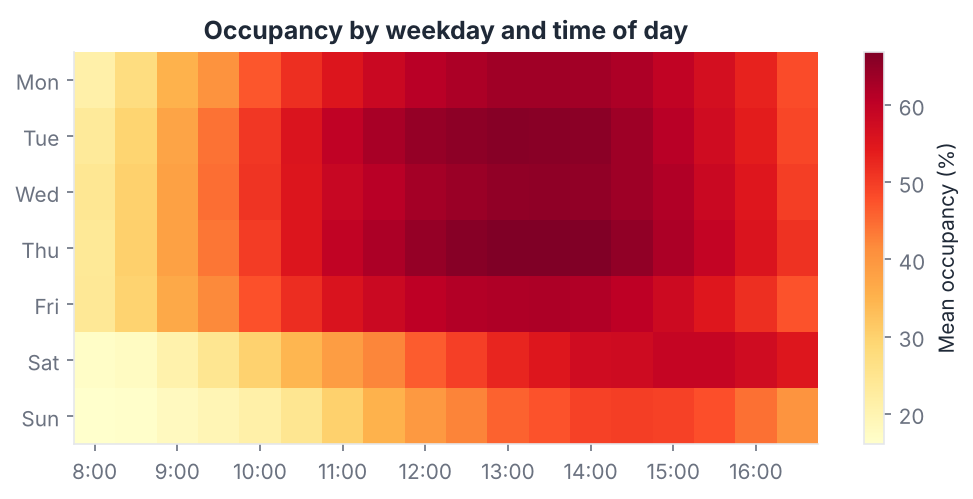

{'Mon': 0.5163,
 'Tue': 0.542,
 'Wed': 0.5421,
 'Thu': 0.5495,
 'Fri': 0.5192,
 'Sat': 0.4308,
 'Sun': 0.3557}

In [7]:
display(Image(ROOT / 'outputs/figures/eda_03_weekday_hour_heatmap.png'))
eda['weekday_mean']

Weekends, especially Sundays, are quieter and start later. This motivates `day_of_week`, `is_weekend` and the same-weekday-last-week features.

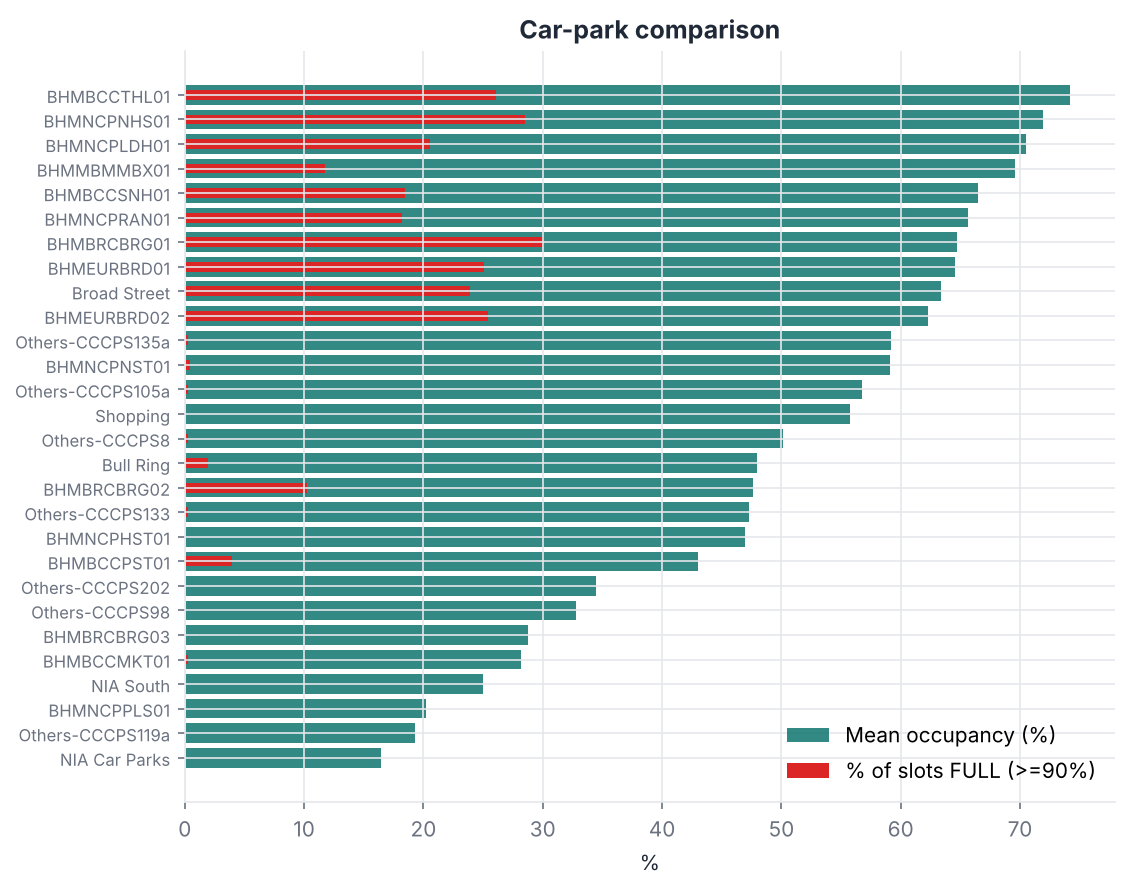

In [8]:
display(Image(ROOT / 'outputs/figures/eda_04_facility_comparison.png'))

Car parks behave very differently (mean occupancy from ~16% to ~74%; some are FULL in a quarter of slots, others never). A car-park identifier is needed so one model can serve them all.

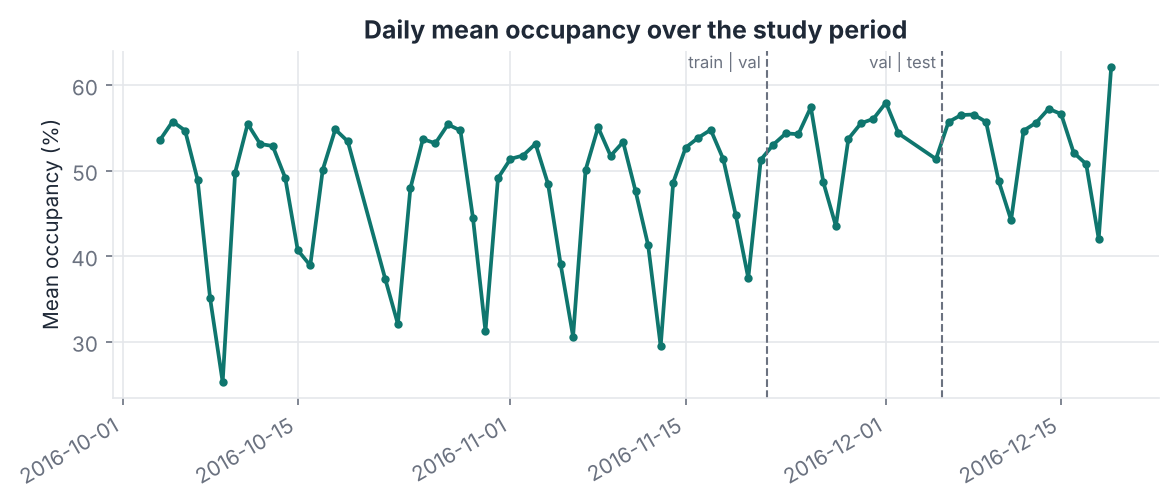

{'train': 0.4762, 'val': 0.5344, 'test': 0.5359}

In [9]:
display(Image(ROOT / 'outputs/figures/eda_05_daily_trend.png'))
eda['mean_rate_by_split']

There is a clear weekly cycle and a rise towards Christmas: the test fortnight (mean 53.6%) is busier than the training period (47.6%). A chronological split therefore tests the model under realistic drift – a random split would hide it.

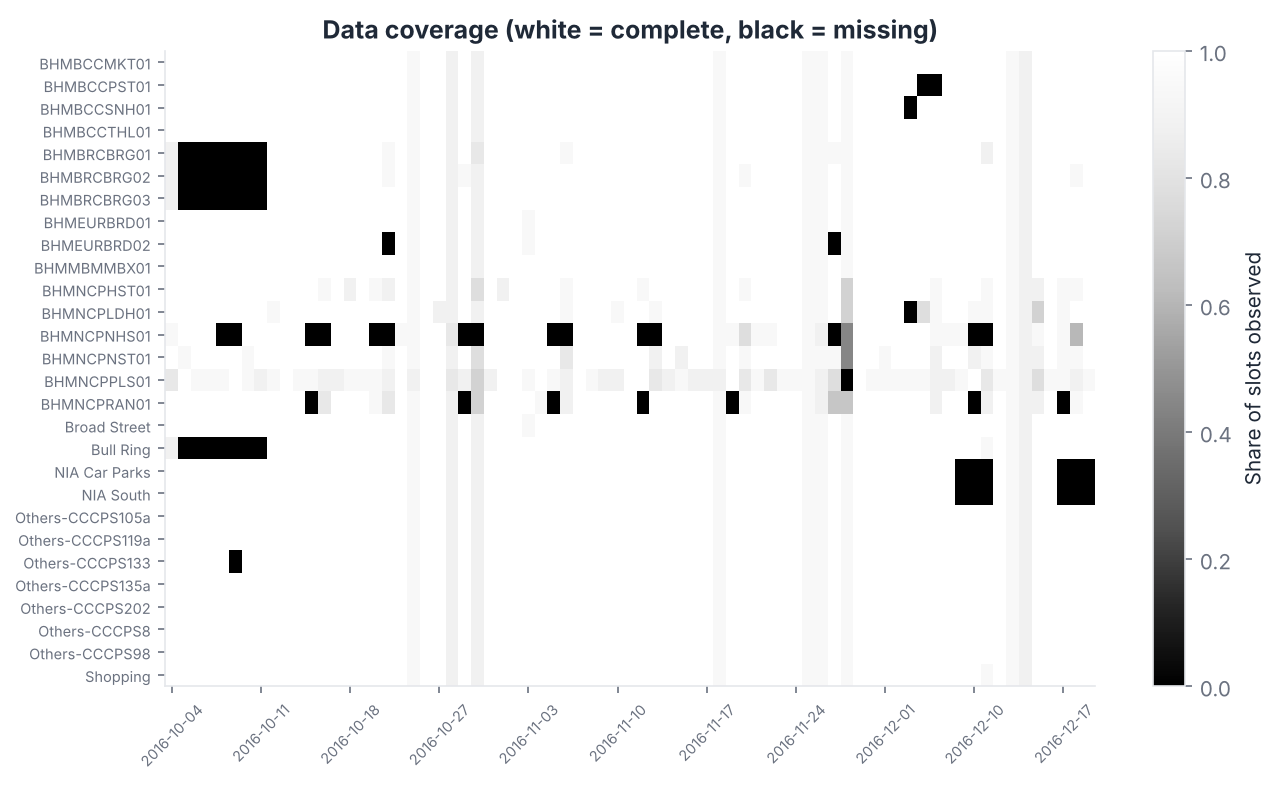

{'BHMNCPNHS01': 23.74,
 'BHMNCPRAN01': 13.01,
 'BHMBRCBRG01': 11.11,
 'BHMBRCBRG02': 10.96,
 'Bull Ring': 10.73}

In [10]:
display(Image(ROOT / 'outputs/figures/eda_06_missing_data_map.png'))
eda['parks_most_missing']

Missing data is concentrated in a few car parks and days, not spread randomly. Tree models handle missing lag features natively; the linear model gets median imputation plus missing-indicator columns.

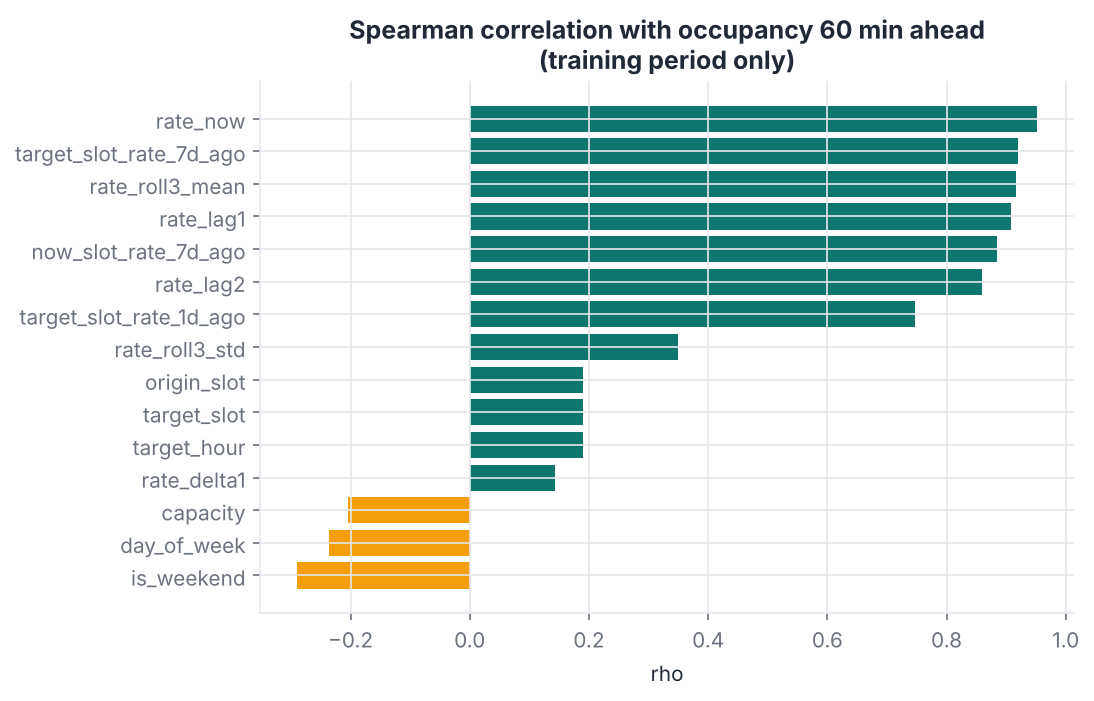

{'rate_now': 0.9518,
 'target_slot_rate_7d_ago': 0.9204,
 'rate_roll3_mean': 0.9173,
 'rate_lag1': 0.9078,
 'now_slot_rate_7d_ago': 0.884,
 'rate_lag2': 0.8594,
 'target_slot_rate_1d_ago': 0.7469,
 'rate_roll3_std': 0.3495,
 'target_hour': 0.1893,
 'origin_slot': 0.1893,
 'target_slot': 0.1893,
 'rate_delta1': 0.1433,
 'capacity': -0.205,
 'day_of_week': -0.2361,
 'is_weekend': -0.2895}

In [11]:
display(Image(ROOT / 'outputs/figures/eda_07_feature_target_correlation.png'))
eda['spearman_with_target_h60']

Current occupancy and last week's value at the target time correlate most with occupancy 60 minutes later. Correlation is computed on the training period only, and it measures association, not cause.

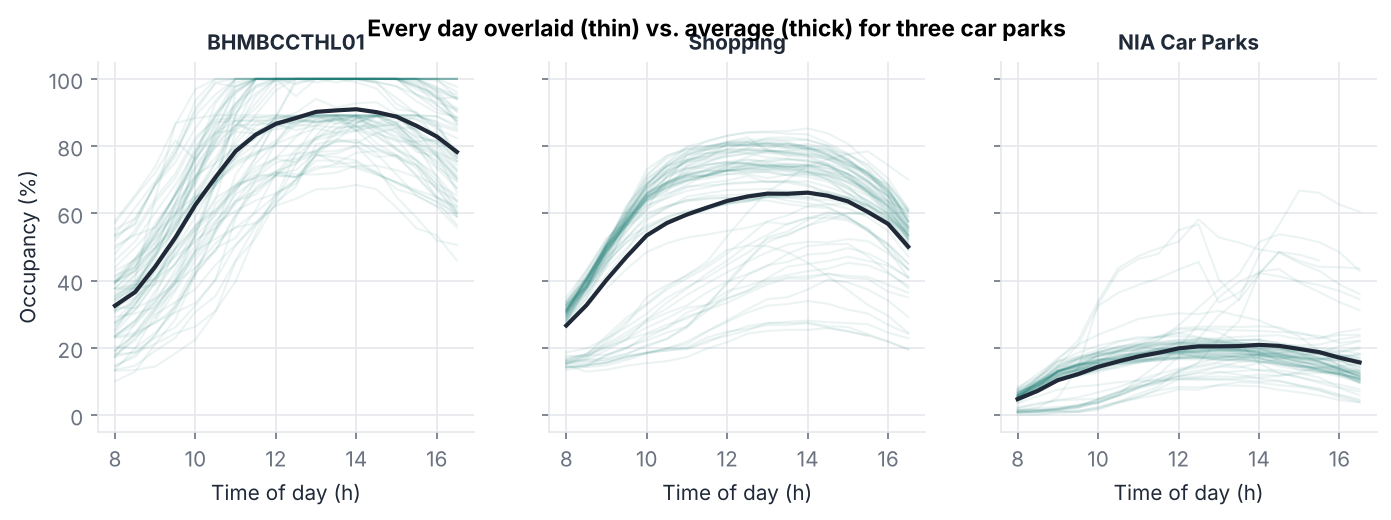

In [12]:
display(Image(ROOT / 'outputs/figures/eda_08_daily_curves_examples.png'))

## Feature engineering
Every feature is computed from information available at the forecast origin.

In [13]:
from src.feature_engineering import build_features, FEATURE_DESCRIPTIONS, split_by_date
pd.Series(FEATURE_DESCRIPTIONS, name='description').to_frame()

,description
park_code,Integer ID of the car park (categorical).
capacity,Total spaces in the car park.
origin_slot,Slot index of the forecast origin (0 = 08:00 ....
target_slot,Slot index of the time being forecast.
target_hour,"Clock time being forecast, in hours (e.g. 13.5..."
day_of_week,0 = Monday ... 6 = Sunday.
is_weekend,1 on Saturday/Sunday.
rate_now,Occupancy rate observed at the origin slot.
rate_lag1,Occupancy rate 30 minutes before the origin (s...
rate_lag2,Occupancy rate 60 minutes before the origin (s...


In [14]:
f60 = build_features(grid, 60)
sp = split_by_date(f60)
pd.DataFrame({k: {'rows': len(v), 'from': v['date'].min().date(), 'to': v['date'].max().date()} for k, v in sp.items()}).T

,rows,from,to
train,19912,2016-10-04,2016-11-21
val,5080,2016-11-22,2016-12-05
test,5739,2016-12-06,2016-12-19


In [15]:
f60[['SystemCodeNumber','slot_time','target_time','rate_now','rate_lag1','target_slot_rate_7d_ago','target_rate','target_status']].head(8)

,SystemCodeNumber,slot_time,target_time,rate_now,rate_lag1,target_slot_rate_7d_ago,target_rate,target_status
0,BHMBCCMKT01,2016-10-04 08:00:00,2016-10-04 09:00:00,0.105719,NaN,NaN,0.138648,LOW
1,BHMBCCMKT01,2016-10-04 08:30:00,2016-10-04 09:30:00,0.110919,0.105719,NaN,0.185442,LOW
2,BHMBCCMKT01,2016-10-04 09:00:00,2016-10-04 10:00:00,0.138648,0.110919,NaN,0.259965,LOW
3,BHMBCCMKT01,2016-10-04 09:30:00,2016-10-04 10:30:00,0.185442,0.138648,NaN,0.306759,LOW
4,BHMBCCMKT01,2016-10-04 10:00:00,2016-10-04 11:00:00,0.259965,0.185442,NaN,0.379549,LOW
5,BHMBCCMKT01,2016-10-04 10:30:00,2016-10-04 11:30:00,0.306759,0.259965,NaN,0.428076,LOW
6,BHMBCCMKT01,2016-10-04 11:00:00,2016-10-04 12:00:00,0.379549,0.306759,NaN,0.448873,LOW
7,BHMBCCMKT01,2016-10-04 11:30:00,2016-10-04 12:30:00,0.428076,0.379549,NaN,0.461005,LOW


In [16]:
f60['target_status'].value_counts(normalize=True).round(3)

target_status
LOW         0.471
MODERATE    0.284
HIGH        0.148
FULL        0.097
Name: proportion, dtype: float64